# DS605 Lab 8 - Decision Trees and Support Vector Machines
**Dataset:** UCI Banknote Authentication (1,372 samples, 4 features, 2 classes)

| Part | Content |
|---|---|
| A | Decision Tree from scratch (Gini / entropy, recursive build, boundaries, tree plot, vs Scikit-learn) |
| B | Linear soft-margin SVM from scratch (hinge loss + subgradient descent, margins, C / lr / iterations study) |
| C | Kernel SVM (linear / polynomial / RBF) on `make_moons` and `make_circles` |
| D | Final comparison on all four features (metrics, timing, complexity) |

**Rules followed:** the Decision Tree and the Linear SVM are implemented with NumPy/Pandas only.
Scikit-learn is used only for comparison models, `train_test_split`, metrics and toy datasets.

*Run all cells from top to bottom. All figures go to `plots/` and all tables to `results/`.*

In [1]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.datasets import make_moons, make_circles
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

os.makedirs("plots", exist_ok=True)
os.makedirs("results", exist_ok=True)
os.makedirs("data", exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
COLORS = ["#2E6FBA", "#E07B39"]                      # class 0 / class 1
POINT_CMAP = ListedColormap(COLORS)
BG_CMAP = ListedColormap(["#BFD5EF", "#F6CFB3"])


def savefig(name):
    plt.tight_layout()
    plt.savefig(f"plots/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()


def show(df, name=None, index=False):
    """Display a DataFrame and optionally save it to results/."""
    if name:
        df.to_csv(f"results/{name}.csv", index=index)
    try:
        from IPython.display import display
        display(df)
    except Exception:
        print(df.to_string())

## 0. Load data and make one consistent train/test split
The loader tries (1) a local copy in `data/`, (2) the UCI repository, (3) OpenML.
Feature names follow the UCI description. The same stratified 80/20 split is reused in every part.

In [2]:
FEATURES = ["variance", "skewness", "curtosis", "entropy"]
LOCAL_CSV = "data/banknote.csv"


def load_banknote():
    if os.path.exists(LOCAL_CSV):
        return pd.read_csv(LOCAL_CSV)
    df = None
    try:
        url = ("https://archive.ics.uci.edu/ml/machine-learning-databases/"
               "00267/data_banknote_authentication.txt")
        df = pd.read_csv(url, header=None, names=FEATURES + ["class"])
        print("Loaded from UCI repository.")
    except Exception as e:
        print("UCI download failed:", type(e).__name__, "- trying OpenML ...")
        from sklearn.datasets import fetch_openml
        raw = fetch_openml(data_id=1462, as_frame=True)          # banknote-authentication
        df = raw.data.copy()
        df.columns = FEATURES
        df["class"] = pd.factorize(raw.target, sort=True)[0]       # -> 0 / 1
        print("Loaded from OpenML.")
    df.to_csv(LOCAL_CSV, index=False)
    return df


df = load_banknote()
print("Shape:", df.shape)
print(df["class"].value_counts().rename("count").to_frame().T)
show(df.describe().T.round(3))

X_all = df[FEATURES].values.astype(float)
y_all = df["class"].values.astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.20, stratify=y_all, random_state=SEED)
print(f"Train: {X_train.shape}, Test: {X_test.shape}")

# Two-feature view (variance, skewness) used for all 2D boundary plots
F2 = [0, 1]
X_train2, X_test2 = X_train[:, F2], X_test[:, F2]
F2_NAMES = [FEATURES[i] for i in F2]

Loaded from UCI repository.
Shape: (1372, 5)
class    0    1
count  762  610


,count,mean,std,min,25%,50%,75%,max
variance,1372.0,0.434,2.843,-7.042,-1.773,0.496,2.821,6.825
skewness,1372.0,1.922,5.869,-13.773,-1.708,2.320,6.815,12.952
curtosis,1372.0,1.398,4.310,-5.286,-1.575,0.617,3.179,17.927
entropy,1372.0,-1.192,2.101,-8.548,-2.413,-0.587,0.395,2.450
class,1372.0,0.445,0.497,0.000,0.000,0.000,1.000,1.000


Train: (1097, 4), Test: (275, 4)


---
# Part A - Decision Tree from Scratch
### A.1 Impurity measures and best split search
For a node with class proportions $p_k$:
$$\text{Gini}=1-\sum_k p_k^2 \qquad \text{Entropy}=-\sum_k p_k\log_2 p_k$$
For every feature, samples are sorted and every midpoint between two consecutive distinct values is a
candidate threshold. Left/right class counts come from cumulative sums, so all thresholds of a feature are
evaluated in one vectorised pass. The split with the largest impurity decrease
$\;I(parent)-\frac{n_L}{n}I(L)-\frac{n_R}{n}I(R)\;$ is chosen.

In [3]:
def gini_from_counts(counts):
    """counts: (..., K) array of class counts -> impurity (...)."""
    n = counts.sum(axis=-1, keepdims=True)
    p = np.divide(counts, n, out=np.zeros_like(counts, dtype=float), where=n > 0)
    return 1.0 - (p ** 2).sum(axis=-1)


def entropy_from_counts(counts):
    n = counts.sum(axis=-1, keepdims=True)
    p = np.divide(counts, n, out=np.zeros_like(counts, dtype=float), where=n > 0)
    logp = np.log2(p, out=np.zeros_like(p), where=p > 0)
    return -(p * logp).sum(axis=-1)


def gini(y, n_classes=None):
    k = n_classes or (y.max() + 1)
    return float(gini_from_counts(np.bincount(y, minlength=k)))


def entropy(y, n_classes=None):
    k = n_classes or (y.max() + 1)
    return float(entropy_from_counts(np.bincount(y, minlength=k)))


IMPURITY = {"gini": gini_from_counts, "entropy": entropy_from_counts}

# quick sanity check
_t = np.array([0, 0, 0, 1, 1, 1])
print("Gini(50/50) =", gini(_t), "| Entropy(50/50) =", entropy(_t))
print("Gini(pure)  =", gini(np.zeros(5, int), 2), "| Entropy(pure) =", entropy(np.zeros(5, int), 2))


def best_split(X, y, n_classes, criterion="gini", min_samples_leaf=1):
    """Return (feature, threshold, gain) of the best split, or (None, None, 0)."""
    n, d = X.shape
    imp = IMPURITY[criterion]
    Y = np.eye(n_classes)[y]
    parent_imp = float(imp(Y.sum(axis=0)))
    best = (None, None, 0.0)
    best_gain = 0.0
    n_left = np.arange(1, n)
    n_right = n - n_left
    for j in range(d):
        order = np.argsort(X[:, j], kind="mergesort")
        xs, Ys = X[order, j], Y[order]
        left = np.cumsum(Ys, axis=0)[:-1]
        right = Ys.sum(axis=0) - left
        valid = (xs[1:] != xs[:-1]) & (n_left >= min_samples_leaf) & (n_right >= min_samples_leaf)
        if not valid.any():
            continue
        weighted = (n_left * imp(left) + n_right * imp(right)) / n
        weighted = np.where(valid, weighted, np.inf)
        i = int(np.argmin(weighted))
        gain = parent_imp - weighted[i]
        if gain > best_gain + 1e-12:
            best_gain = gain
            best = (j, 0.5 * (xs[i] + xs[i + 1]), gain)
    return best

Gini(50/50) = 0.5 | Entropy(50/50) = 1.0
Gini(pure)  = 0.0 | Entropy(pure) = -0.0


### A.2 Recursive tree construction + prediction
**Stopping rules:** node is pure, `max_depth` reached, `n < min_samples_split`, no split satisfies
`min_samples_leaf`, or the best gain is `<= min_impurity_decrease`.

In [4]:
class Node:
    __slots__ = ("feature", "threshold", "left", "right", "counts",
                 "prediction", "impurity", "n_samples", "depth", "gain", "id")

    def __init__(self, counts, impurity, depth):
        self.feature = self.threshold = self.left = self.right = None
        self.counts = counts
        self.prediction = int(np.argmax(counts))
        self.impurity = impurity
        self.n_samples = int(counts.sum())
        self.depth = depth
        self.gain = 0.0
        self.id = None

    @property
    def is_leaf(self):
        return self.left is None


class ManualDecisionTree:
    def __init__(self, criterion="gini", max_depth=None, min_samples_split=2,
                 min_samples_leaf=1, min_impurity_decrease=0.0):
        assert criterion in IMPURITY
        self.criterion = criterion
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.min_impurity_decrease = min_impurity_decrease

    # ---------- training ----------
    def fit(self, X, y):
        X = np.asarray(X, float)
        self.classes_, y_enc = np.unique(y, return_inverse=True)
        self.n_classes_ = len(self.classes_)
        self.n_features_ = X.shape[1]
        self.root_ = self._grow(X, y_enc, depth=0)
        self._number_nodes()
        return self

    def _grow(self, X, y, depth):
        counts = np.bincount(y, minlength=self.n_classes_)
        node = Node(counts, float(IMPURITY[self.criterion](counts)), depth)
        stop = (node.impurity == 0.0
                or (self.max_depth is not None and depth >= self.max_depth)
                or len(y) < self.min_samples_split
                or len(y) < 2 * self.min_samples_leaf)
        if stop:
            return node
        j, thr, gain = best_split(X, y, self.n_classes_, self.criterion, self.min_samples_leaf)
        if j is None or gain <= self.min_impurity_decrease:
            return node
        mask = X[:, j] <= thr
        node.feature, node.threshold, node.gain = j, float(thr), float(gain)
        node.left = self._grow(X[mask], y[mask], depth + 1)
        node.right = self._grow(X[~mask], y[~mask], depth + 1)
        return node

    def _number_nodes(self):
        stack, i = [self.root_], 0
        while stack:
            nd = stack.pop(0)
            nd.id = i
            i += 1
            if not nd.is_leaf:
                stack += [nd.left, nd.right]

    # ---------- prediction ----------
    def predict(self, X):
        X = np.asarray(X, float)
        out = np.empty(len(X), dtype=int)
        self._route(self.root_, X, np.arange(len(X)), out)
        return self.classes_[out]

    def _route(self, node, X, idx, out):
        if len(idx) == 0:
            return
        if node.is_leaf:
            out[idx] = node.prediction
            return
        go_left = X[idx, node.feature] <= node.threshold
        self._route(node.left, X, idx[go_left], out)
        self._route(node.right, X, idx[~go_left], out)

    # ---------- inspection ----------
    def _nodes(self):
        stack, res = [self.root_], []
        while stack:
            nd = stack.pop(0)
            res.append(nd)
            if not nd.is_leaf:
                stack += [nd.left, nd.right]
        return res

    @property
    def n_nodes(self):
        return len(self._nodes())

    @property
    def n_leaves(self):
        return sum(nd.is_leaf for nd in self._nodes())

    @property
    def depth(self):
        return max(nd.depth for nd in self._nodes())

    def export_text(self, feature_names):
        lines = []

        def rec(nd, indent):
            pad = "|   " * indent
            if nd.is_leaf:
                lines.append(f"{pad}|--- class: {self.classes_[nd.prediction]}  "
                             f"(samples={nd.n_samples}, counts={nd.counts.tolist()})")
                return
            f = feature_names[nd.feature]
            lines.append(f"{pad}|--- {f} <= {nd.threshold:.4f}")
            rec(nd.left, indent + 1)
            lines.append(f"{pad}|--- {f} >  {nd.threshold:.4f}")
            rec(nd.right, indent + 1)

        rec(self.root_, 0)
        return "\n".join(lines)

    def rules_table(self, feature_names):
        rows = []
        for nd in self._nodes():
            rows.append({
                "node": nd.id, "depth": nd.depth,
                "type": "leaf" if nd.is_leaf else "split",
                "rule": "-" if nd.is_leaf else f"{feature_names[nd.feature]} <= {nd.threshold:.4f}",
                "impurity": round(nd.impurity, 4), "samples": nd.n_samples,
                "class_counts": nd.counts.tolist(),
                "prediction": int(self.classes_[nd.prediction]),
                "impurity_decrease": round(nd.gain, 4) if not nd.is_leaf else "-"})
        return pd.DataFrame(rows)

### A.3 Helper plots: decision boundary and tree drawing

In [5]:
def plot_boundary(ax, predict_fn, X, y, title, X_test=None, y_test=None, res=300, pad=0.5,
                  xlabel="variance", ylabel="skewness"):
    allX = X if X_test is None else np.vstack([X, X_test])
    x0, x1 = allX[:, 0].min() - pad, allX[:, 0].max() + pad
    y0, y1 = allX[:, 1].min() - pad, allX[:, 1].max() + pad
    xx, yy = np.meshgrid(np.linspace(x0, x1, res), np.linspace(y0, y1, res))
    Z = predict_fn(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=[-0.5, 0.5, 1.5], cmap=BG_CMAP)
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap=POINT_CMAP, s=14, edgecolor="k", linewidth=0.2, alpha=0.8)
    if X_test is not None:
        ax.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap=POINT_CMAP, s=26, marker="X",
                   edgecolor="k", linewidth=0.5)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.grid(False)


def plot_manual_tree(tree, feature_names, class_names=("class 0", "class 1"), title="", ax=None):
    pos, counter = {}, [0]

    def layout(nd):
        if nd.is_leaf:
            pos[nd.id] = (counter[0], -nd.depth)
            counter[0] += 1
        else:
            layout(nd.left)
            layout(nd.right)
            pos[nd.id] = ((pos[nd.left.id][0] + pos[nd.right.id][0]) / 2, -nd.depth)

    layout(tree.root_)
    n_leaves, depth = counter[0], tree.depth
    if ax is None:
        _, ax = plt.subplots(figsize=(max(9, 1.5 * n_leaves), 1.9 * (depth + 1)))
    for nd in tree._nodes():
        if not nd.is_leaf:
            for ch, lab in ((nd.left, "True"), (nd.right, "False")):
                (x0, y0), (x1, y1) = pos[nd.id], pos[ch.id]
                ax.plot([x0, x1], [y0, y1], color="gray", lw=1, zorder=1)
                ax.text((x0 + x1) / 2, (y0 + y1) / 2 + 0.05, lab, fontsize=7, color="gray", ha="center")
    for nd in tree._nodes():
        x, y = pos[nd.id]
        major = int(tree.classes_[nd.prediction])
        if nd.is_leaf:
            txt = f"{class_names[major]}\nsamples={nd.n_samples}\n{nd.counts.tolist()}"
        else:
            txt = (f"{feature_names[nd.feature]}\n<= {nd.threshold:.3f}\n"
                   f"{tree.criterion}={nd.impurity:.3f}\nsamples={nd.n_samples}")
        ax.text(x, y, txt, ha="center", va="center", fontsize=7.5, zorder=2,
                bbox=dict(boxstyle="round,pad=0.35", fc=BG_CMAP.colors[major], ec=COLORS[major], lw=1.4))
    ax.set_xlim(-0.8, n_leaves - 0.2)
    ax.set_ylim(-depth - 0.7, 0.7)
    ax.axis("off")
    ax.set_title(title, fontsize=11)
    return ax

### A.4 Manual tree vs Scikit-learn tree: decision boundaries (variance, skewness)
Same hyper-parameters (`max_depth=4`) for both implementations and both criteria.

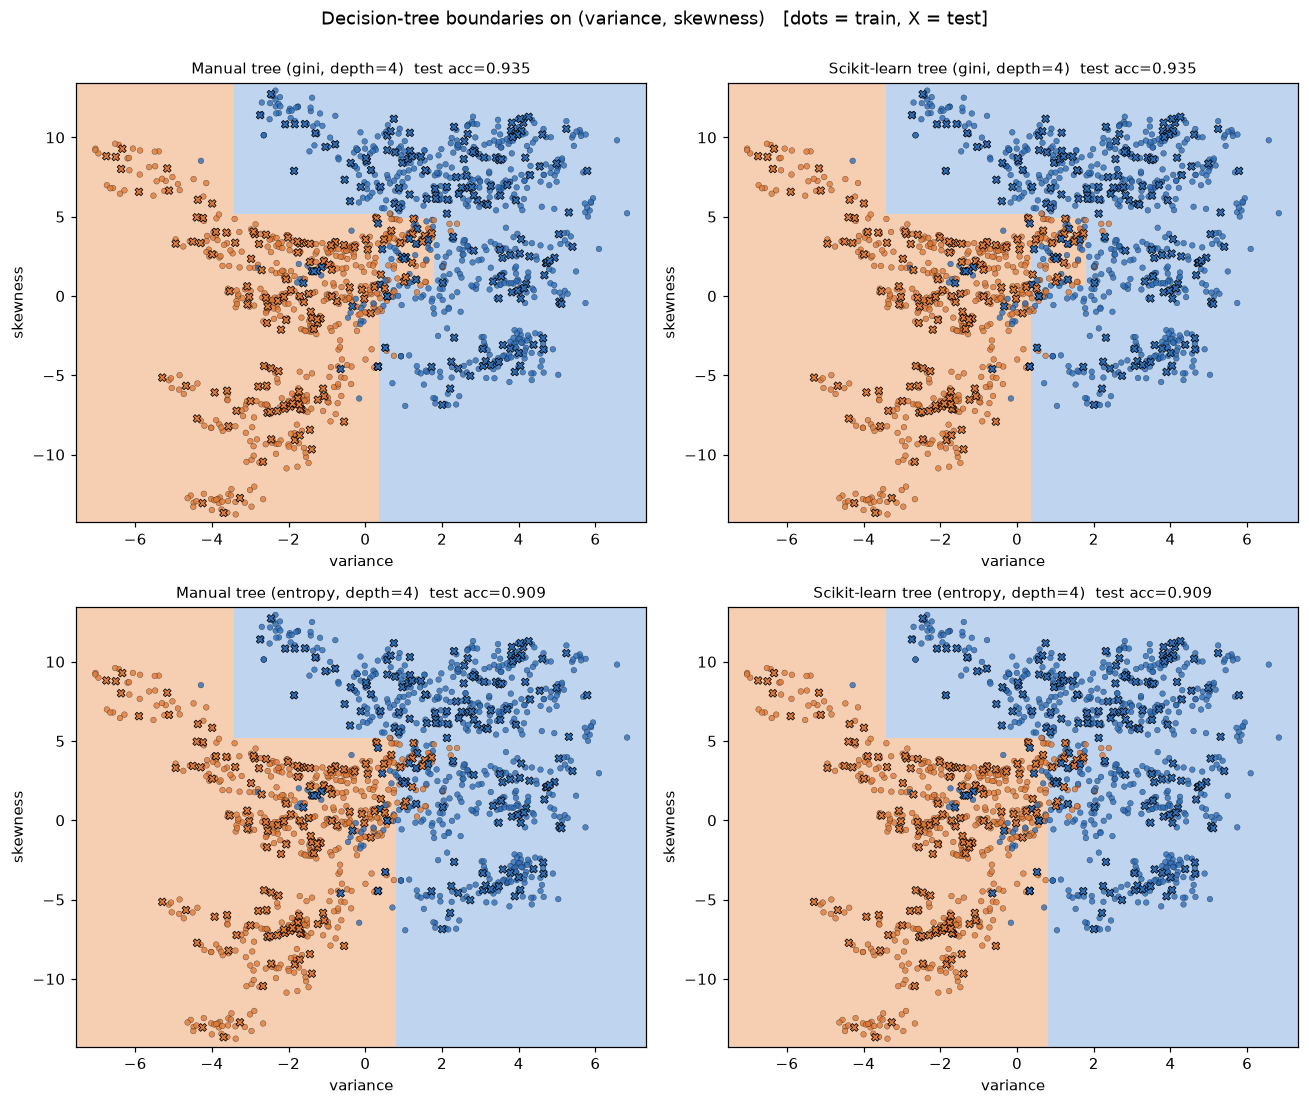

In [6]:
DEPTH_MAIN = 4
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
trees2 = {}
for r, crit in enumerate(["gini", "entropy"]):
    m = ManualDecisionTree(criterion=crit, max_depth=DEPTH_MAIN).fit(X_train2, y_train)
    s = DecisionTreeClassifier(criterion=crit, max_depth=DEPTH_MAIN, random_state=SEED).fit(X_train2, y_train)
    trees2[crit] = (m, s)
    acc_m = accuracy_score(y_test, m.predict(X_test2))
    acc_s = accuracy_score(y_test, s.predict(X_test2))
    plot_boundary(axes[r, 0], m.predict, X_train2, y_train,
                  f"Manual tree ({crit}, depth={DEPTH_MAIN})  test acc={acc_m:.3f}", X_test2, y_test)
    plot_boundary(axes[r, 1], s.predict, X_train2, y_train,
                  f"Scikit-learn tree ({crit}, depth={DEPTH_MAIN})  test acc={acc_s:.3f}", X_test2, y_test)
fig.suptitle("Decision-tree boundaries on (variance, skewness)   [dots = train, X = test]", y=1.0)
savefig("A_tree_boundaries_manual_vs_sklearn")

### A.5 Learned manual tree and its split rules

|--- variance <= 0.7651
|   |--- skewness <= 5.1608
|   |   |--- variance <= 0.3202
|   |   |   |--- variance <= -0.4586
|   |   |   |   |--- class: 1  (samples=346, counts=[9, 337])
|   |   |   |--- variance >  -0.4586
|   |   |   |   |--- class: 1  (samples=67, counts=[11, 56])
|   |   |--- variance >  0.3202
|   |   |   |--- skewness <= 3.2197
|   |   |   |   |--- class: 0  (samples=39, counts=[22, 17])
|   |   |   |--- skewness >  3.2197
|   |   |   |   |--- class: 1  (samples=12, counts=[0, 12])
|   |--- skewness >  5.1608
|   |   |--- variance <= -3.4311
|   |   |   |--- variance <= -4.3819
|   |   |   |   |--- class: 1  (samples=29, counts=[0, 29])
|   |   |   |--- variance >  -4.3819
|   |   |   |   |--- class: 1  (samples=3, counts=[1, 2])
|   |   |--- variance >  -3.4311
|   |   |   |--- skewness <= 5.3646
|   |   |   |   |--- class: 0  (samples=2, counts=[1, 1])
|   |   |   |--- skewness >  5.3646
|   |   |   |   |--- class: 0  (samples=95, counts=[95, 0])
|--- variance >  0

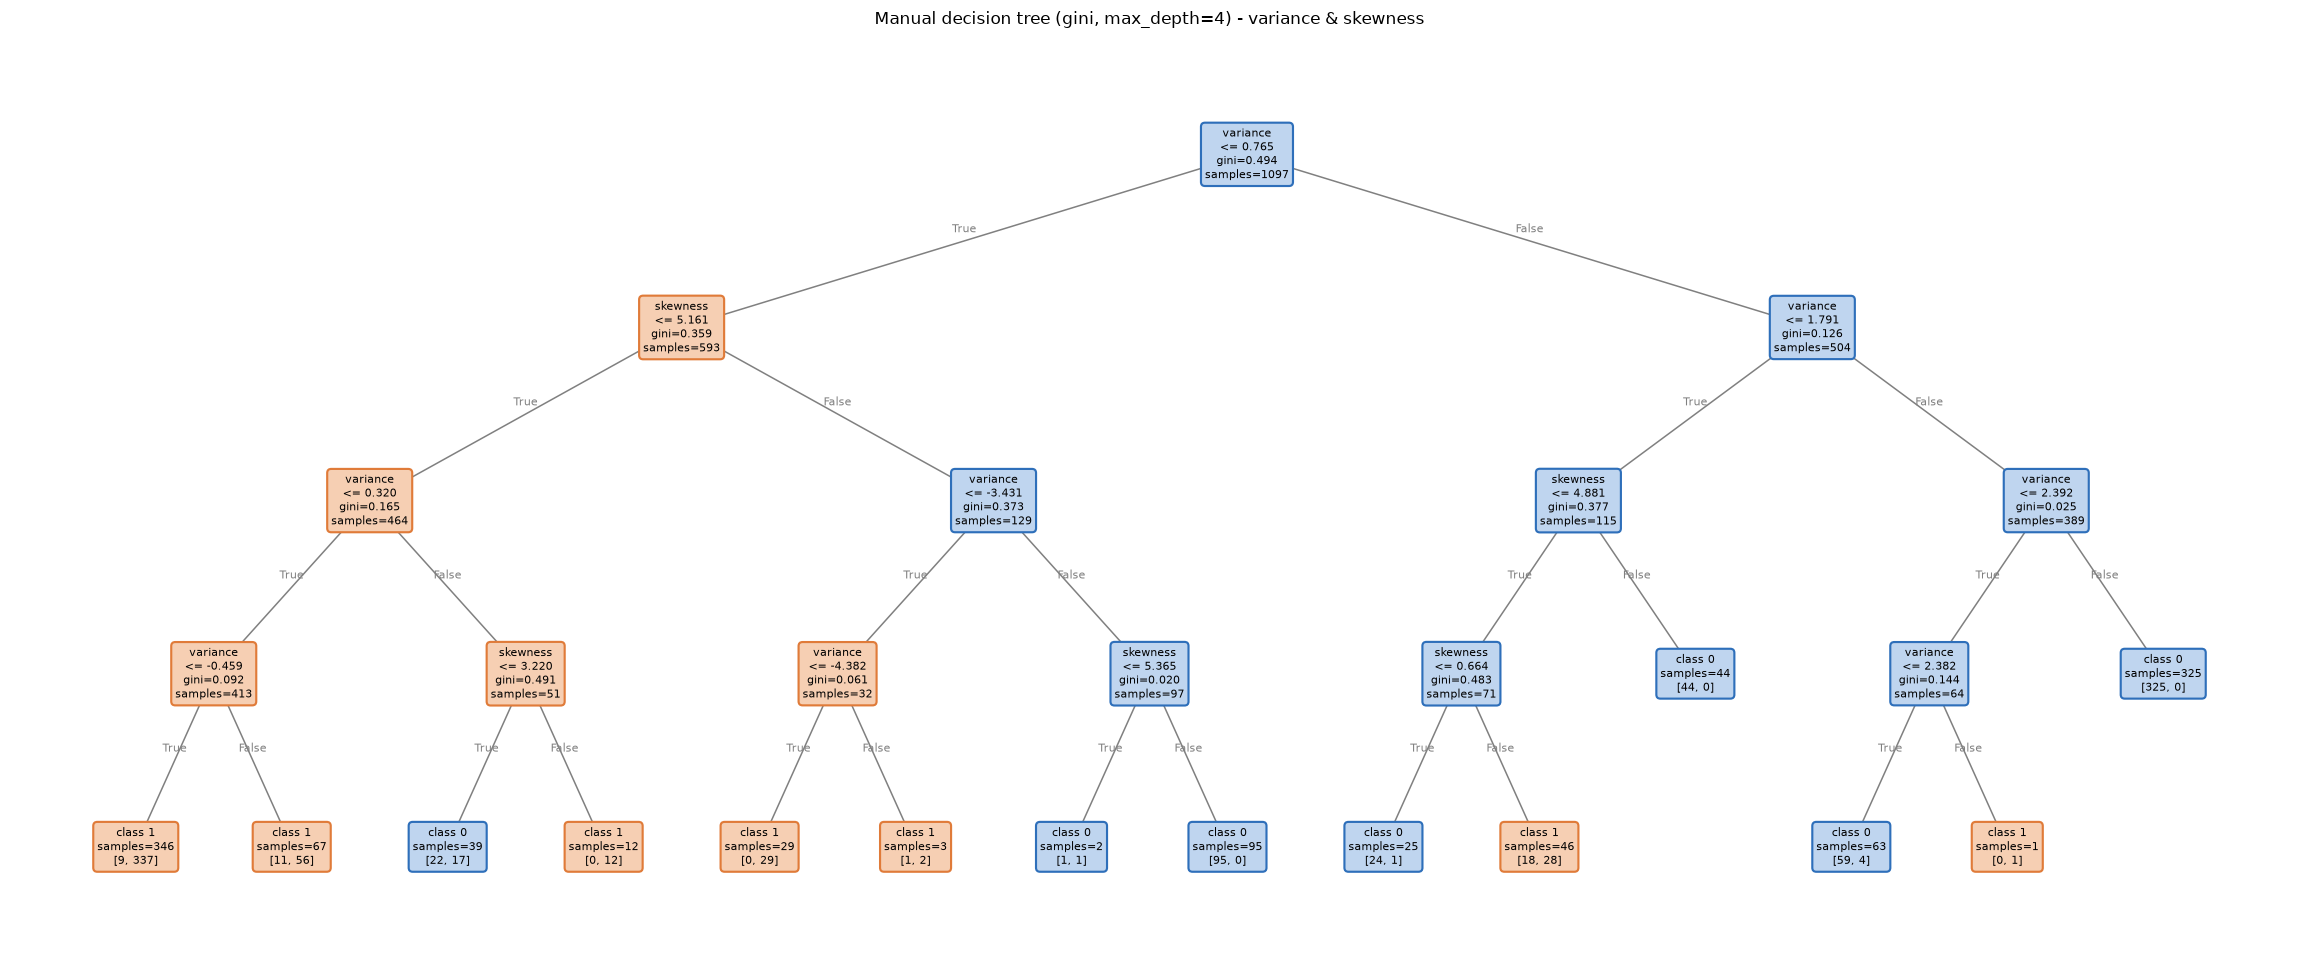

,node,depth,type,rule,impurity,samples,class_counts,prediction,impurity_decrease
0,0,0,split,variance <= 0.7651,0.4939,1097,"[609, 488]",0,0.2421
1,1,1,split,skewness <= 5.1608,0.3589,593,"[139, 454]",1,0.1489
2,2,1,split,variance <= 1.7907,0.1258,504,"[470, 34]",0,0.0202
3,3,2,split,variance <= 0.3202,0.1646,464,"[42, 422]",1,0.0287
4,4,2,split,variance <= -3.4311,0.3731,129,"[97, 32]",0,0.3427
5,5,2,split,skewness <= 4.8814,0.3772,115,"[86, 29]",0,0.0788
6,6,2,split,variance <= 2.3921,0.0254,389,"[384, 5]",0,0.0017
7,7,3,split,variance <= -0.4586,0.0922,413,"[20, 393]",1,0.0052
8,8,3,split,skewness <= 3.2197,0.4906,51,"[22, 29]",1,0.1145
9,9,3,split,variance <= -4.3819,0.0605,32,"[1, 31]",1,0.0189


In [7]:
manual_tree = trees2["gini"][0]
print(manual_tree.export_text(F2_NAMES))
print(f"\nNodes={manual_tree.n_nodes}, leaves={manual_tree.n_leaves}, depth={manual_tree.depth}")

fig, ax = plt.subplots(figsize=(max(12, 1.5 * manual_tree.n_leaves), 9))
plot_manual_tree(manual_tree, F2_NAMES, ("class 0", "class 1"),
                 title=f"Manual decision tree (gini, max_depth={DEPTH_MAIN}) - variance & skewness", ax=ax)
savefig("A_manual_tree_visualization")

rules = manual_tree.rules_table(F2_NAMES)
show(rules, "A_manual_tree_split_rules")

### A.6 Explore criterion and max_depth; compare with Scikit-learn
`agreement` = fraction of test samples on which manual and Scikit-learn trees predict the same label.

,criterion,max_depth,manual_train_acc,manual_test_acc,sklearn_train_acc,sklearn_test_acc,manual_leaves,sklearn_leaves,agreement,manual_fit_s,sklearn_fit_s
0,gini,1,0.8423,0.8291,0.8423,0.8291,2,2,1.0000,0.0028,0.0037
1,gini,2,0.9015,0.8764,0.9015,0.8764,4,4,1.0000,0.0057,0.0035
2,gini,3,0.9289,0.9091,0.9289,0.9091,8,8,1.0000,0.0102,0.0038
3,gini,4,0.9435,0.9345,0.9435,0.9345,14,14,1.0000,0.0125,0.0042
4,gini,5,0.9480,0.9309,0.9480,0.9309,22,22,1.0000,0.0187,0.0044
5,gini,6,0.9572,0.9273,0.9572,0.9309,31,31,0.9964,0.0227,0.0046
6,gini,8,0.9809,0.9164,0.9809,0.9200,52,52,0.9964,0.0355,0.0051
7,gini,10,0.9954,0.9200,0.9954,0.9236,65,65,0.9964,0.0405,0.0046
8,gini,None,1.0000,0.9200,1.0000,0.9200,74,74,0.9927,0.0422,0.0040
9,entropy,1,0.8423,0.8291,0.8423,0.8291,2,2,1.0000,0.0022,0.0029


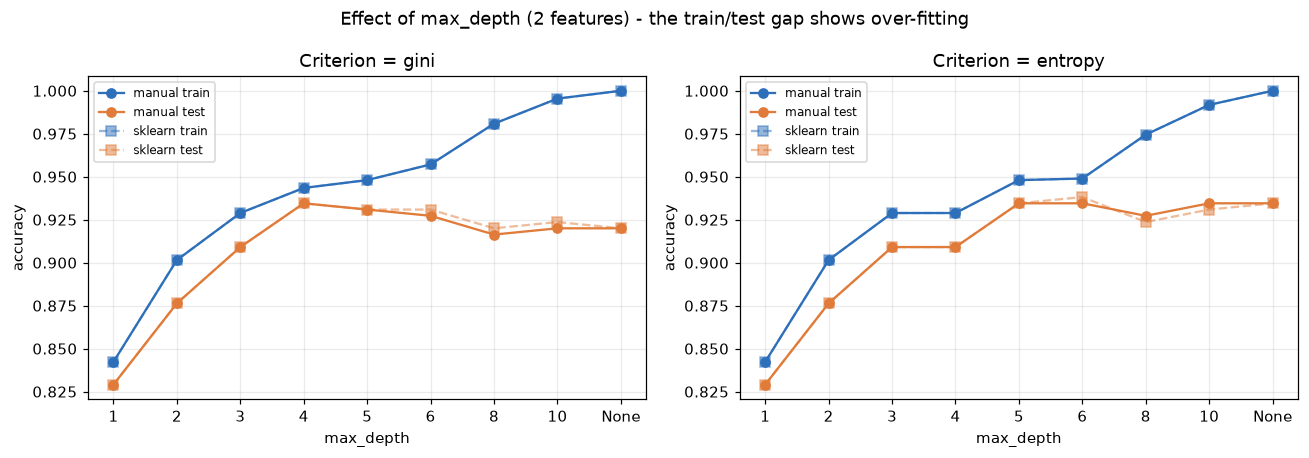

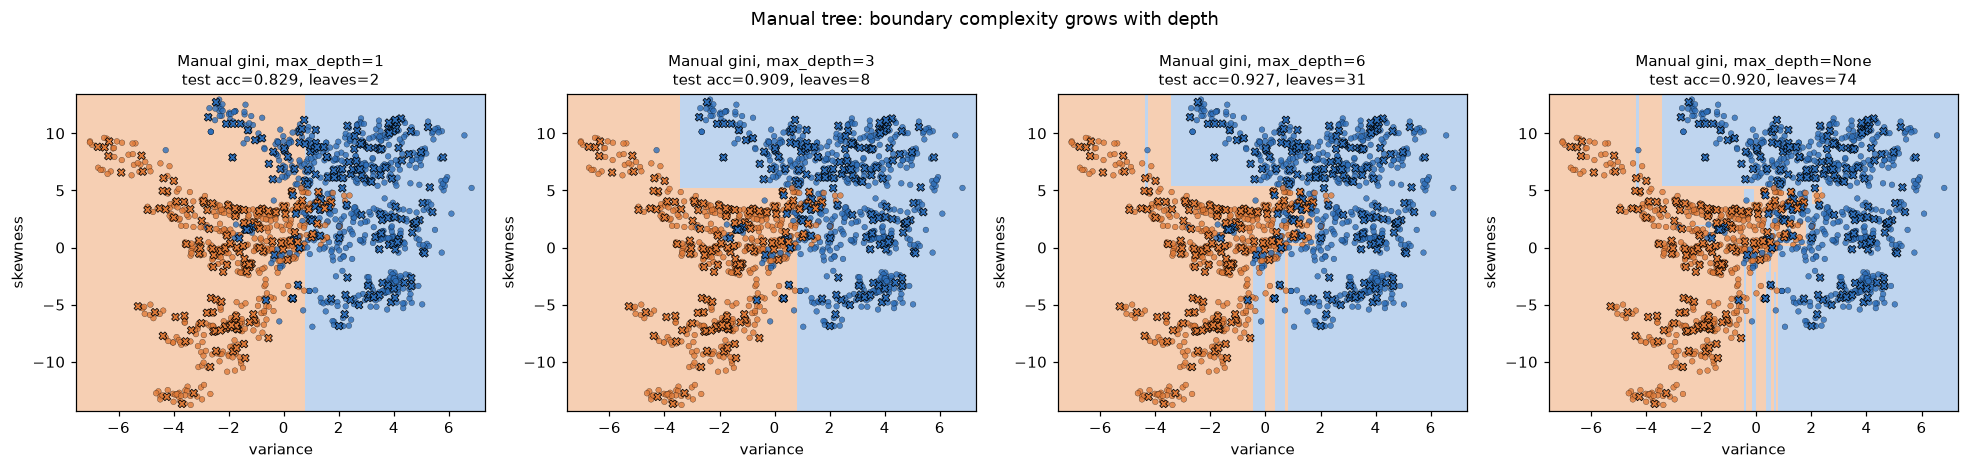

In [8]:
depths = [1, 2, 3, 4, 5, 6, 8, 10, None]
rows = []
for crit in ["gini", "entropy"]:
    for d in depths:
        t0 = time.perf_counter()
        m = ManualDecisionTree(criterion=crit, max_depth=d).fit(X_train2, y_train)
        t_m = time.perf_counter() - t0
        t0 = time.perf_counter()
        s = DecisionTreeClassifier(criterion=crit, max_depth=d, random_state=SEED).fit(X_train2, y_train)
        t_s = time.perf_counter() - t0
        pm, ps = m.predict(X_test2), s.predict(X_test2)
        rows.append({"criterion": crit, "max_depth": "None" if d is None else d,
                     "manual_train_acc": accuracy_score(y_train, m.predict(X_train2)),
                     "manual_test_acc": accuracy_score(y_test, pm),
                     "sklearn_train_acc": accuracy_score(y_train, s.predict(X_train2)),
                     "sklearn_test_acc": accuracy_score(y_test, ps),
                     "manual_leaves": m.n_leaves, "sklearn_leaves": s.get_n_leaves(),
                     "agreement": float((pm == ps).mean()),
                     "manual_fit_s": t_m, "sklearn_fit_s": t_s})
tree_grid = pd.DataFrame(rows)
show(tree_grid.round(4), "A_tree_criterion_depth_grid")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
xt = list(range(len(depths)))
for ax, crit in zip(axes, ["gini", "entropy"]):
    g = tree_grid[tree_grid.criterion == crit]
    ax.plot(xt, g.manual_train_acc, "o-", c=COLORS[0], label="manual train")
    ax.plot(xt, g.manual_test_acc, "o-", c=COLORS[1], label="manual test")
    ax.plot(xt, g.sklearn_train_acc, "s--", c=COLORS[0], alpha=0.5, label="sklearn train")
    ax.plot(xt, g.sklearn_test_acc, "s--", c=COLORS[1], alpha=0.5, label="sklearn test")
    ax.set_xticks(xt)
    ax.set_xticklabels(g.max_depth.astype(str))
    ax.set_xlabel("max_depth")
    ax.set_ylabel("accuracy")
    ax.set_title(f"Criterion = {crit}")
    ax.legend(fontsize=8)
fig.suptitle("Effect of max_depth (2 features) - the train/test gap shows over-fitting")
savefig("A_depth_vs_accuracy")

# boundary change with depth (manual)
fig, axes = plt.subplots(1, 4, figsize=(18, 4.3))
for ax, d in zip(axes, [1, 3, 6, None]):
    m = ManualDecisionTree("gini", max_depth=d).fit(X_train2, y_train)
    plot_boundary(ax, m.predict, X_train2, y_train,
                  f"Manual gini, max_depth={d}\ntest acc={accuracy_score(y_test, m.predict(X_test2)):.3f}, "
                  f"leaves={m.n_leaves}", X_test2, y_test)
fig.suptitle("Manual tree: boundary complexity grows with depth")
savefig("A_manual_tree_depth_boundaries")

---
# Part B - Linear Soft-Margin SVM from Scratch
### B.1 Scaling with training statistics and labels in {-1, +1}
### B.2 Model
Primal objective (same form Scikit-learn uses, so `C` is directly comparable):
$$J(w,b)=\tfrac12\lVert w\rVert^2 + C\sum_i \max\!\big(0,\;1-y_i(w^\top x_i+b)\big)$$
Dividing by $Cn$ gives the **subgradient** used for full-batch descent
(only samples with margin $<1$, i.e. *margin violators*, contribute):
$$\nabla_w=\frac{w}{Cn}-\frac1n\sum_{i\in V}y_i x_i,\qquad \nabla_b=-\frac1n\sum_{i\in V}y_i$$
Step size: $\eta_t=\eta_0/(1+\text{decay}\cdot t)$.

In [9]:
class ManualStandardScaler:
    """z = (x - mean_train) / std_train  (statistics from the training set only)."""
    def fit(self, X):
        self.mean_ = X.mean(axis=0)
        self.std_ = X.std(axis=0)
        self.std_[self.std_ == 0] = 1.0
        return self

    def transform(self, X):
        return (X - self.mean_) / self.std_

    def fit_transform(self, X):
        return self.fit(X).transform(X)


def primal_objective(w, b, X, y_pm, C):
    hinge = np.maximum(0.0, 1.0 - y_pm * (X @ w + b))
    return 0.5 * float(w @ w) + C * float(hinge.sum())


class ManualLinearSVM:
    def __init__(self, C=1.0, lr=0.1, n_iters=2000, lr_decay=0.01):
        self.C, self.lr, self.n_iters, self.lr_decay = C, lr, n_iters, lr_decay

    def fit(self, X, y_pm):
        n, d = X.shape
        self.w_, self.b_ = np.zeros(d), 0.0
        self.history_ = []
        for t in range(self.n_iters):
            margins = y_pm * (X @ self.w_ + self.b_)
            viol = margins < 1
            grad_w = self.w_ / (self.C * n) - (y_pm[viol, None] * X[viol]).sum(axis=0) / n
            grad_b = -y_pm[viol].sum() / n
            eta = self.lr / (1.0 + self.lr_decay * t)
            self.w_ -= eta * grad_w
            self.b_ -= eta * grad_b
            self.history_.append(primal_objective(self.w_, self.b_, X, y_pm, self.C))
        return self

    def decision_function(self, X):
        return X @ self.w_ + self.b_

    def predict(self, X):                       # returns -1 / +1
        return np.where(self.decision_function(X) >= 0, 1, -1)

    def predict01(self, X):                     # returns 0 / 1
        return (self.predict(X) + 1) // 2

    @property
    def margin_width(self):
        return 2.0 / np.linalg.norm(self.w_)


scaler2 = ManualStandardScaler().fit(X_train2)
Xs_train2, Xs_test2 = scaler2.transform(X_train2), scaler2.transform(X_test2)
ytr_pm, yte_pm = 2 * y_train - 1, 2 * y_test - 1          # {0,1} -> {-1,+1}
print("Train mean after scaling:", Xs_train2.mean(0).round(6), " std:", Xs_train2.std(0).round(6))
print("Label mapping:", dict(zip(*np.unique(ytr_pm, return_counts=True))))

Train mean after scaling: [-0.  0.]  std: [1. 1.]
Label mapping: {np.int64(-1): np.int64(609), np.int64(1): np.int64(488)}


### B.3 Manual vs Scikit-learn linear SVM: separating line, margins and violators
Dashed lines are the $f(x)=\pm1$ margins, solid is $f(x)=0$. Red rings = **margin-violating samples**
($y_i f(x_i)<1$, i.e. inside the margin or misclassified). Squares = Scikit-learn support vectors.

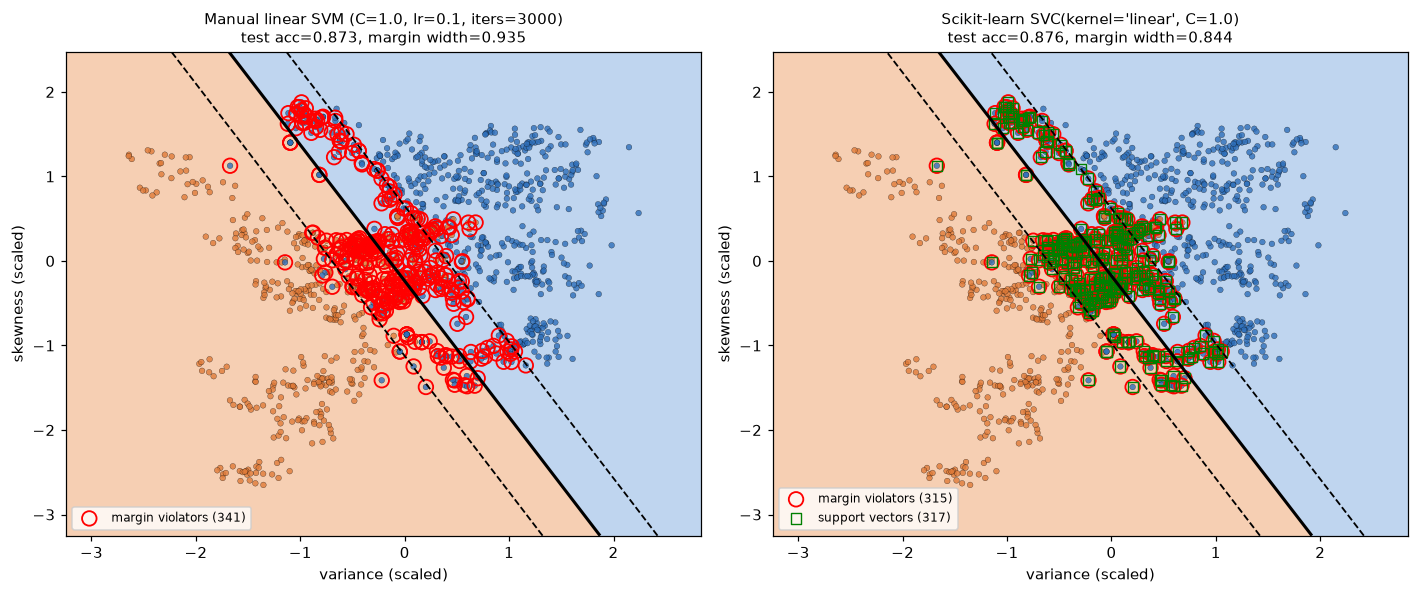

,model,w_variance,w_skewness,bias,||w||,margin_width,primal_objective,train_acc,test_acc
0,manual,-1.8166,-1.1281,-0.2673,2.1384,0.9353,313.2126,0.8769,0.8727
1,sklearn,-2.0093,-1.2550,-0.2211,2.3690,0.8442,311.9589,0.8806,0.8764


Prediction agreement on test set: 0.9891 | cosine similarity of w vectors: 1.0000


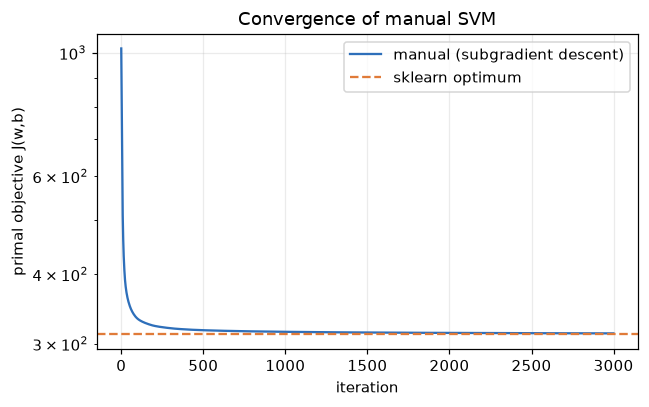

In [10]:
def plot_svm_margins(ax, w, b, X, y_pm, title, sv=None, res=300, pad=0.6):
    x0, x1 = X[:, 0].min() - pad, X[:, 0].max() + pad
    y0, y1 = X[:, 1].min() - pad, X[:, 1].max() + pad
    xx, yy = np.meshgrid(np.linspace(x0, x1, res), np.linspace(y0, y1, res))
    f = (np.c_[xx.ravel(), yy.ravel()] @ w + b).reshape(xx.shape)
    ax.contourf(xx, yy, f, levels=[-1e9, 0, 1e9], cmap=BG_CMAP)
    ax.contour(xx, yy, f, levels=[-1, 0, 1], colors="k", linestyles=["--", "-", "--"], linewidths=[1.2, 2, 1.2])
    y01 = (y_pm + 1) // 2
    ax.scatter(X[:, 0], X[:, 1], c=y01, cmap=POINT_CMAP, s=14, edgecolor="k", linewidth=0.2, alpha=0.8)
    viol = y_pm * (X @ w + b) < 1
    ax.scatter(X[viol, 0], X[viol, 1], s=90, facecolors="none", edgecolors="red", linewidths=1.2,
               label=f"margin violators ({viol.sum()})")
    if sv is not None:
        ax.scatter(sv[:, 0], sv[:, 1], s=45, marker="s", facecolors="none", edgecolors="green",
                   linewidths=0.9, label=f"support vectors ({len(sv)})")
    ax.set_xlim(x0, x1)
    ax.set_ylim(y0, y1)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("variance (scaled)")
    ax.set_ylabel("skewness (scaled)")
    ax.legend(loc="lower left", fontsize=8)
    ax.grid(False)


C_MAIN = 1.0
svm_m = ManualLinearSVM(C=C_MAIN, lr=0.1, n_iters=3000).fit(Xs_train2, ytr_pm)
svm_s = SVC(kernel="linear", C=C_MAIN).fit(Xs_train2, y_train)
w_s, b_s = svm_s.coef_[0], svm_s.intercept_[0]

acc_m = accuracy_score(y_test, svm_m.predict01(Xs_test2))
acc_s = accuracy_score(y_test, svm_s.predict(Xs_test2))
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
plot_svm_margins(axes[0], svm_m.w_, svm_m.b_, Xs_train2, ytr_pm,
                 f"Manual linear SVM (C={C_MAIN}, lr=0.1, iters=3000)\ntest acc={acc_m:.3f}, margin width={svm_m.margin_width:.3f}")
plot_svm_margins(axes[1], w_s, b_s, Xs_train2, ytr_pm,
                 f"Scikit-learn SVC(kernel='linear', C={C_MAIN})\ntest acc={acc_s:.3f}, margin width={2/np.linalg.norm(w_s):.3f}",
                 sv=svm_s.support_vectors_)
savefig("B_svm_manual_vs_sklearn_margins")

cmp = pd.DataFrame({
    "model": ["manual", "sklearn"],
    "w_variance": [svm_m.w_[0], w_s[0]], "w_skewness": [svm_m.w_[1], w_s[1]], "bias": [svm_m.b_, b_s],
    "||w||": [np.linalg.norm(svm_m.w_), np.linalg.norm(w_s)],
    "margin_width": [svm_m.margin_width, 2 / np.linalg.norm(w_s)],
    "primal_objective": [primal_objective(svm_m.w_, svm_m.b_, Xs_train2, ytr_pm, C_MAIN),
                         primal_objective(w_s, b_s, Xs_train2, ytr_pm, C_MAIN)],
    "train_acc": [accuracy_score(y_train, svm_m.predict01(Xs_train2)), accuracy_score(y_train, svm_s.predict(Xs_train2))],
    "test_acc": [acc_m, acc_s]})
show(cmp.round(4), "B_svm_manual_vs_sklearn")
agree = (svm_m.predict01(Xs_test2) == svm_s.predict(Xs_test2)).mean()
cos = svm_m.w_ @ w_s / (np.linalg.norm(svm_m.w_) * np.linalg.norm(w_s))
print(f"Prediction agreement on test set: {agree:.4f} | cosine similarity of w vectors: {cos:.4f}")

fig, ax = plt.subplots(figsize=(6, 3.8))
ax.plot(svm_m.history_, c=COLORS[0], label="manual (subgradient descent)")
ax.axhline(primal_objective(w_s, b_s, Xs_train2, ytr_pm, C_MAIN), c=COLORS[1], ls="--", label="sklearn optimum")
ax.set_yscale("log")
ax.set_xlabel("iteration")
ax.set_ylabel("primal objective J(w,b)")
ax.set_title("Convergence of manual SVM")
ax.legend()
savefig("B_svm_convergence")

### B.4 Effect of regularisation C
Small C -> wide margin, many violators (strong regularisation). Large C -> narrow margin, fewer violators.

,C,manual_test_acc,sklearn_test_acc,manual_margin_width,sklearn_margin_width,manual_violators,sklearn_violators,sklearn_n_SV,manual_objective,sklearn_objective
0,0.001,0.8618,0.8618,3.3976,3.3976,911,911,912,0.7374,0.7374
1,0.010,0.8873,0.8873,1.5974,1.5962,514,513,516,4.3562,4.3562
2,0.100,0.8836,0.8836,1.0441,1.0033,360,352,355,33.3426,33.3281
3,1.000,0.8727,0.8764,0.9353,0.8442,341,315,317,313.2126,311.9589
4,10.000,0.8727,0.8764,0.9236,0.8232,337,308,311,3107.8262,3093.9828
5,100.000,0.8727,0.8764,0.9225,0.8233,337,308,312,31053.4974,30913.2517


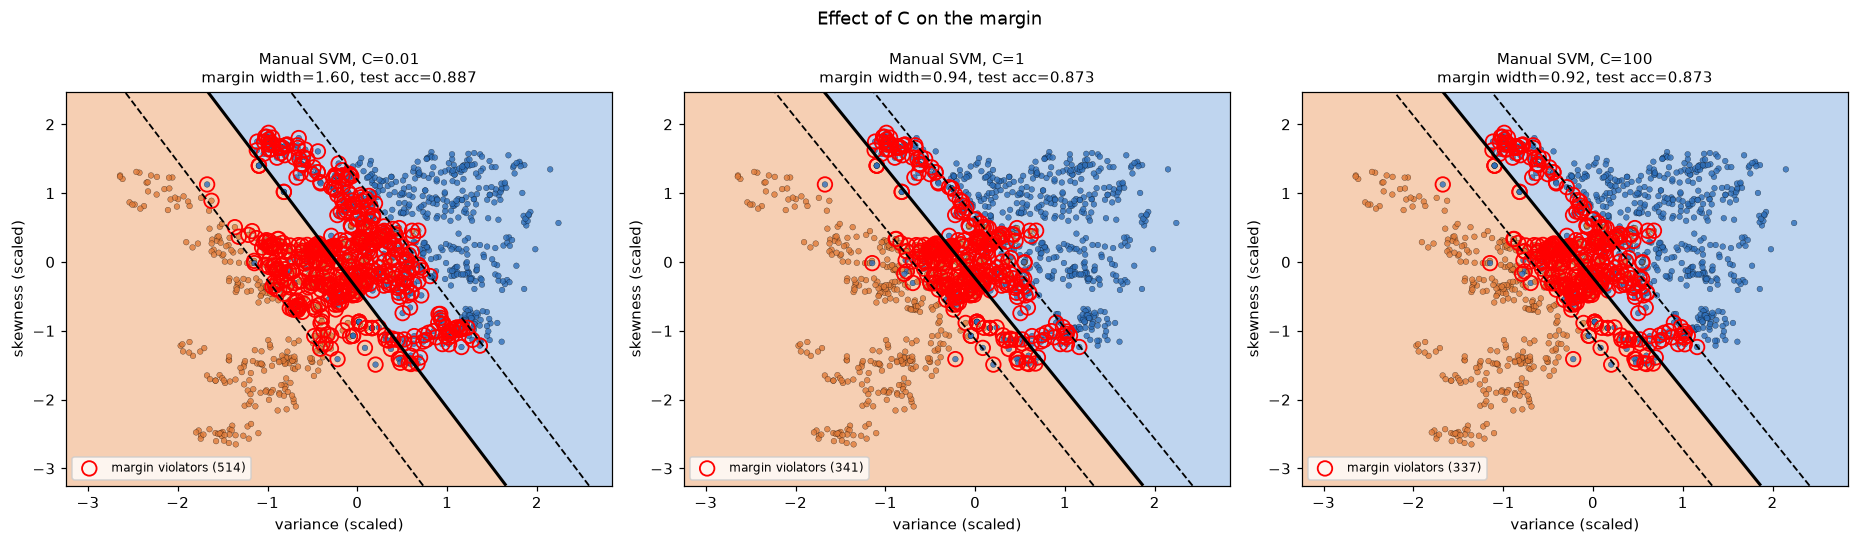

In [11]:
Cs = [0.001, 0.01, 0.1, 1, 10, 100]
rows = []
for C in Cs:
    m = ManualLinearSVM(C=C, lr=0.1, n_iters=3000).fit(Xs_train2, ytr_pm)
    s = SVC(kernel="linear", C=C).fit(Xs_train2, y_train)
    ws, bs = s.coef_[0], s.intercept_[0]
    rows.append({"C": C,
                 "manual_test_acc": accuracy_score(y_test, m.predict01(Xs_test2)),
                 "sklearn_test_acc": accuracy_score(y_test, s.predict(Xs_test2)),
                 "manual_margin_width": m.margin_width, "sklearn_margin_width": 2 / np.linalg.norm(ws),
                 "manual_violators": int((ytr_pm * m.decision_function(Xs_train2) < 1).sum()),
                 "sklearn_violators": int((ytr_pm * (Xs_train2 @ ws + bs) < 1).sum()),
                 "sklearn_n_SV": int(len(s.support_vectors_)),
                 "manual_objective": primal_objective(m.w_, m.b_, Xs_train2, ytr_pm, C),
                 "sklearn_objective": primal_objective(ws, bs, Xs_train2, ytr_pm, C)})
c_study = pd.DataFrame(rows)
show(c_study.round(4), "B_study_C")

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, C in zip(axes, [0.01, 1, 100]):
    m = ManualLinearSVM(C=C, lr=0.1, n_iters=3000).fit(Xs_train2, ytr_pm)
    plot_svm_margins(ax, m.w_, m.b_, Xs_train2, ytr_pm,
                     f"Manual SVM, C={C}\nmargin width={m.margin_width:.2f}, "
                     f"test acc={accuracy_score(y_test, m.predict01(Xs_test2)):.3f}")
fig.suptitle("Effect of C on the margin")
savefig("B_study_C_margins")

### B.5 Effect of learning rate and number of iterations

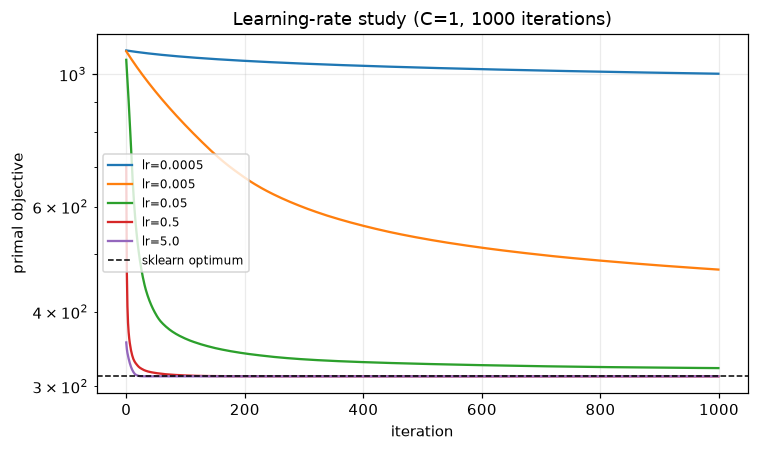

,learning_rate,final_objective,test_acc,margin_width,||w||
0,0.0005,1002.4754,0.8764,19.8273,0.1009
1,0.0050,470.9531,0.8873,2.5329,0.7896
2,0.0500,322.0396,0.8873,1.1496,1.7398
3,0.5000,311.9707,0.8764,0.8524,2.3463
4,5.0000,311.9601,0.8764,0.8442,2.3690


,iterations,final_objective,train_acc,test_acc,margin_width
0,5,712.1947,0.8788,0.8764,4.8583
1,20,407.0436,0.8833,0.8873,2.0353
2,50,352.9242,0.8824,0.8873,1.5374
3,200,323.2434,0.8806,0.8909,1.1709
4,1000,315.2468,0.8833,0.8836,0.9982
5,5000,312.6608,0.8769,0.8727,0.9147


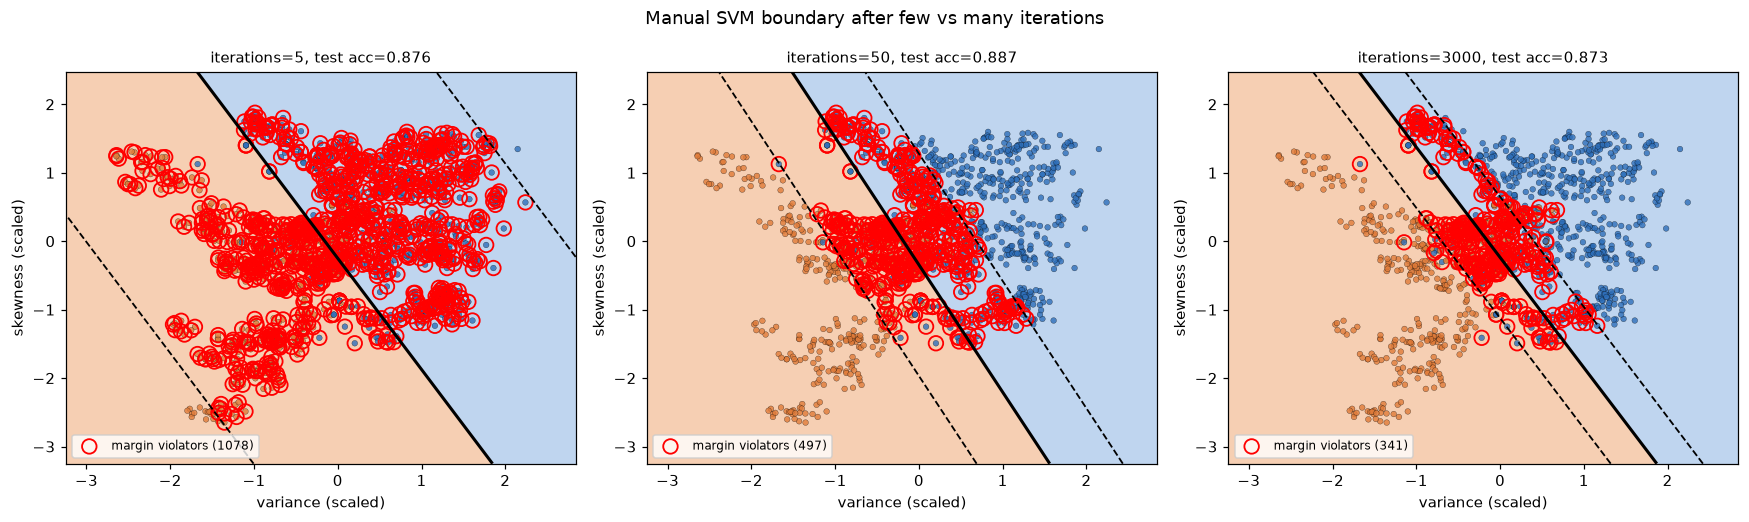

In [12]:
lrs = [0.0005, 0.005, 0.05, 0.5, 5.0]
fig, ax = plt.subplots(figsize=(7, 4.2))
rows = []
for lr in lrs:
    m = ManualLinearSVM(C=1.0, lr=lr, n_iters=1000).fit(Xs_train2, ytr_pm)
    ax.plot(m.history_, label=f"lr={lr}")
    rows.append({"learning_rate": lr, "final_objective": m.history_[-1],
                 "test_acc": accuracy_score(y_test, m.predict01(Xs_test2)),
                 "margin_width": m.margin_width, "||w||": np.linalg.norm(m.w_)})
ax.axhline(primal_objective(w_s, b_s, Xs_train2, ytr_pm, 1.0), c="k", ls="--", lw=1, label="sklearn optimum")
ax.set_yscale("log")
ax.set_xlabel("iteration")
ax.set_ylabel("primal objective")
ax.set_title("Learning-rate study (C=1, 1000 iterations)")
ax.legend(fontsize=8)
savefig("B_study_learning_rate")
lr_study = pd.DataFrame(rows)
show(lr_study.round(4), "B_study_learning_rate")

its = [5, 20, 50, 200, 1000, 5000]
rows = []
for it in its:
    m = ManualLinearSVM(C=1.0, lr=0.1, n_iters=it).fit(Xs_train2, ytr_pm)
    rows.append({"iterations": it, "final_objective": m.history_[-1],
                 "train_acc": accuracy_score(y_train, m.predict01(Xs_train2)),
                 "test_acc": accuracy_score(y_test, m.predict01(Xs_test2)),
                 "margin_width": m.margin_width})
it_study = pd.DataFrame(rows)
show(it_study.round(4), "B_study_iterations")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, it in zip(axes, [5, 50, 3000]):
    m = ManualLinearSVM(C=1.0, lr=0.1, n_iters=it).fit(Xs_train2, ytr_pm)
    plot_svm_margins(ax, m.w_, m.b_, Xs_train2, ytr_pm,
                     f"iterations={it}, test acc={accuracy_score(y_test, m.predict01(Xs_test2)):.3f}")
fig.suptitle("Manual SVM boundary after few vs many iterations")
savefig("B_study_iterations_margins")

---
# Part C - Kernel SVM and Nonlinear Boundaries
Two 2-D nonlinear datasets are generated; Scikit-learn SVMs with **linear**, **polynomial (degree 3)** and
**RBF** kernels are trained and their boundaries compared.

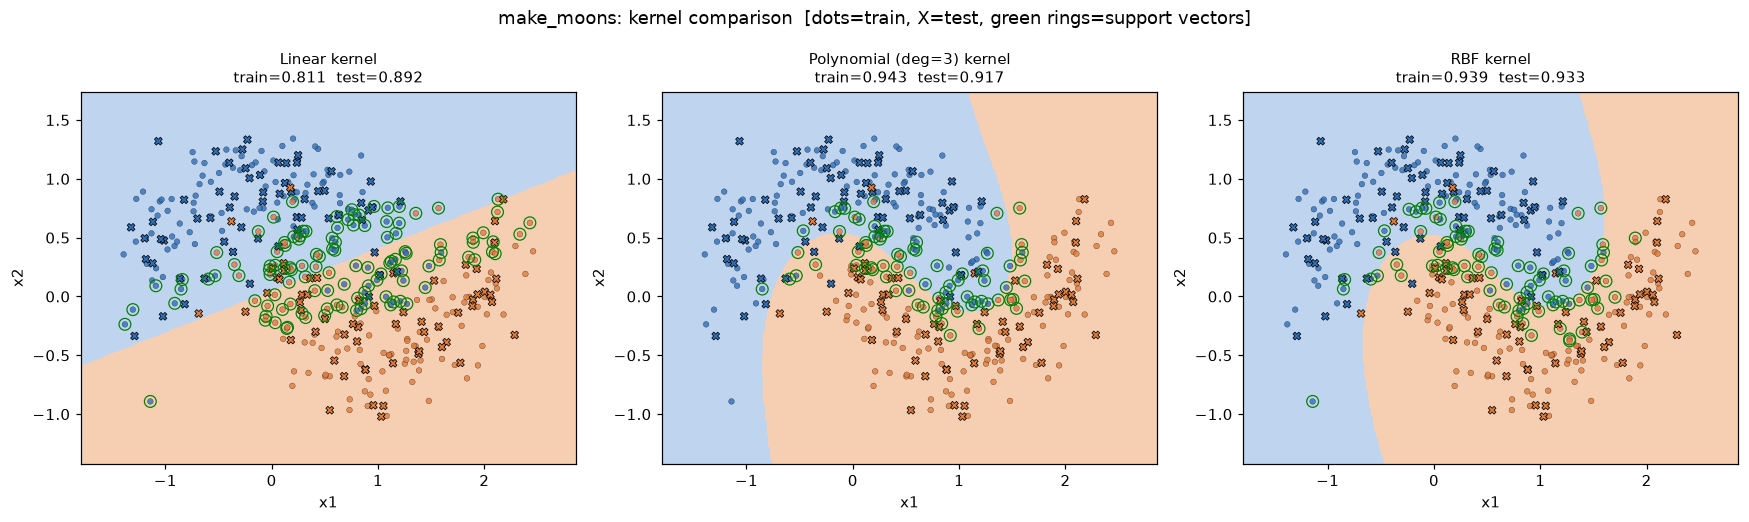

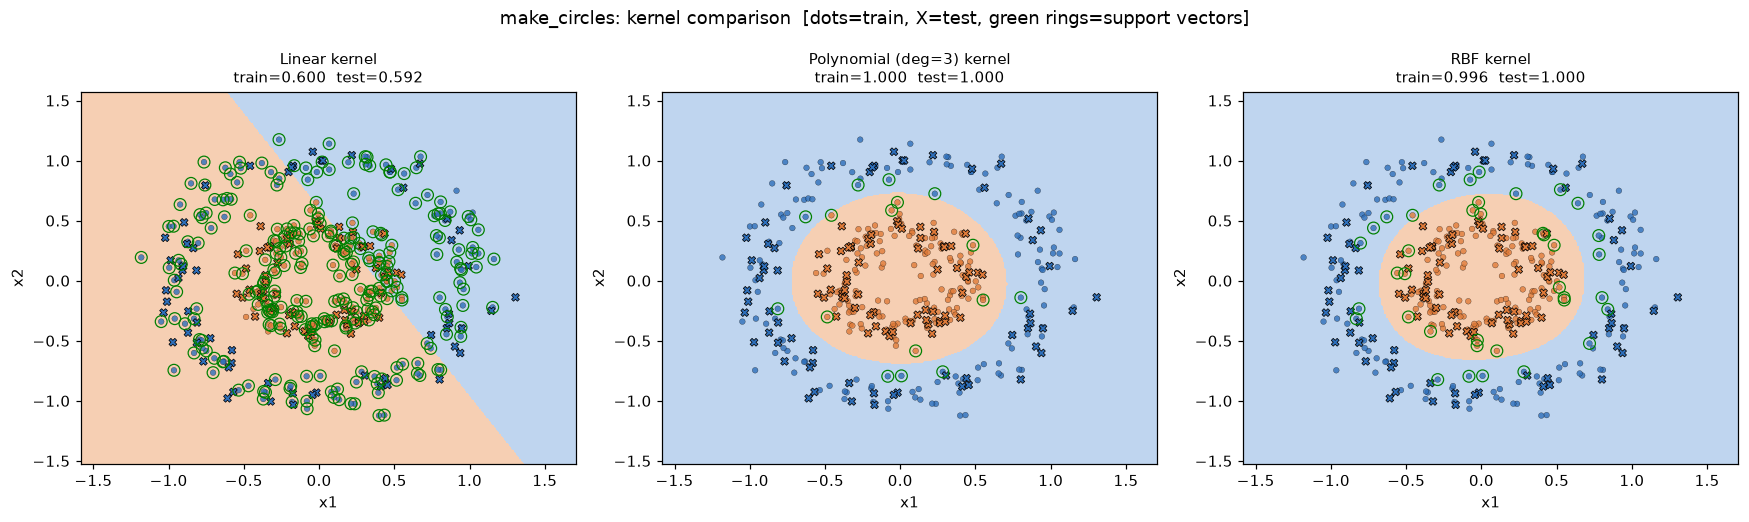

,dataset,kernel,train_acc,test_acc,n_support_vectors
0,make_moons,Linear,0.8107,0.8917,116
1,make_moons,Polynomial (deg=3),0.9429,0.9167,74
2,make_moons,RBF,0.9393,0.9333,85
3,make_circles,Linear,0.6000,0.5917,275
4,make_circles,Polynomial (deg=3),1.0000,1.0000,16
5,make_circles,RBF,0.9964,1.0000,38


In [13]:
def kernel_experiment(X, y, name):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, stratify=y, random_state=SEED)
    models = {
        "Linear": SVC(kernel="linear", C=1.0),
        "Polynomial (deg=3)": SVC(kernel="poly", degree=3, coef0=1, C=1.0, gamma="scale"),
        "RBF": SVC(kernel="rbf", C=1.0, gamma="scale"),
    }
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
    rows = []
    for ax, (k, mdl) in zip(axes, models.items()):
        mdl.fit(Xtr, ytr)
        tr, te = accuracy_score(ytr, mdl.predict(Xtr)), accuracy_score(yte, mdl.predict(Xte))
        plot_boundary(ax, mdl.predict, Xtr, ytr, f"{k} kernel\ntrain={tr:.3f}  test={te:.3f}",
                      Xte, yte, xlabel="x1", ylabel="x2", pad=0.4)
        ax.scatter(*mdl.support_vectors_.T, s=60, facecolors="none", edgecolors="green", linewidths=0.8)
        rows.append({"dataset": name, "kernel": k, "train_acc": tr, "test_acc": te,
                     "n_support_vectors": int(len(mdl.support_vectors_))})
    fig.suptitle(f"{name}: kernel comparison  [dots=train, X=test, green rings=support vectors]")
    savefig(f"C_kernels_{name}")
    return pd.DataFrame(rows)


Xm, ym = make_moons(n_samples=400, noise=0.25, random_state=SEED)
Xc, yc = make_circles(n_samples=400, noise=0.10, factor=0.4, random_state=SEED)
kernel_results = pd.concat([kernel_experiment(Xm, ym, "make_moons"),
                            kernel_experiment(Xc, yc, "make_circles")], ignore_index=True)
show(kernel_results.round(4), "C_kernel_results")

### Why can a nonlinear kernel help?
* A linear SVM can only draw a **straight line (hyperplane)**. When the classes are interleaved (moons) or
  nested (circles) no straight line separates them, so a linear model under-fits whatever the value of `C`.
* A kernel $K(x,x')=\phi(x)^\top\phi(x')$ implicitly maps the data to a higher-dimensional space where a
  *linear* separator exists; the resulting boundary is **curved** in the original space - without computing
  $\phi$ explicitly (the "kernel trick").
* **Polynomial** kernel $(\gamma x^\top x'+r)^d$ adds feature interactions up to degree $d$: smooth global curves.
* **RBF** kernel $\exp(-\gamma\lVert x-x'\rVert^2)$ corresponds to an infinite-dimensional feature space and
  builds *local* bumps around support vectors, so it adapts to arbitrary shapes (nested circles, moons).
  `gamma` controls flexibility (large -> wiggly / over-fit) and `C` controls the margin/error trade-off.
* Cost: more hyper-parameters, more support vectors, slower prediction and a less interpretable model.

---
# Part D - Final Comparison on the Banknote Dataset (all 4 features)
Same stratified split as in all earlier parts. Features are scaled with **training-set statistics for the SVMs**
(trees are scale-invariant and use raw features).

Models: Manual DT, Scikit-learn DT, Manual Linear SVM, Scikit-learn Linear SVM, Scikit-learn RBF SVM.

In [14]:
scaler4 = ManualStandardScaler().fit(X_train)
Xs_train, Xs_test = scaler4.transform(X_train), scaler4.transform(X_test)
ytr_pm4 = 2 * y_train - 1

TREE_DEPTH, SVM_C = 5, 10.0
candidates = {
    "Manual Decision Tree":   dict(make=lambda: ManualDecisionTree("gini", max_depth=TREE_DEPTH),
                                   scaled=False, to01=lambda p: p, manual_svm=False),
    "Sklearn Decision Tree":  dict(make=lambda: DecisionTreeClassifier(criterion="gini", max_depth=TREE_DEPTH, random_state=SEED),
                                   scaled=False, to01=lambda p: p, manual_svm=False),
    "Manual Linear SVM":      dict(make=lambda: ManualLinearSVM(C=SVM_C, lr=0.1, n_iters=3000),
                                   scaled=True, to01=lambda p: p, manual_svm=True),
    "Sklearn Linear SVM":     dict(make=lambda: SVC(kernel="linear", C=SVM_C),
                                   scaled=True, to01=lambda p: p, manual_svm=False),
    "Sklearn RBF SVM":        dict(make=lambda: SVC(kernel="rbf", C=1.0, gamma="scale"),
                                   scaled=True, to01=lambda p: p, manual_svm=False),
}

rows, preds, fitted = [], {}, {}
for name, cfg in candidates.items():
    Xtr = Xs_train if cfg["scaled"] else X_train
    Xte = Xs_test if cfg["scaled"] else X_test
    ytr_fit = ytr_pm4 if cfg["manual_svm"] else y_train

    # training time (mean of 5 repeats)
    t_fit = []
    for _ in range(5):
        mdl = cfg["make"]()
        t0 = time.perf_counter()
        mdl.fit(Xtr, ytr_fit)
        t_fit.append(time.perf_counter() - t0)
    # prediction time on the test set (mean of 30 repeats)
    t_pred = []
    for _ in range(30):
        t0 = time.perf_counter()
        mdl.predict01(Xte) if cfg["manual_svm"] else mdl.predict(Xte)
        t_pred.append(time.perf_counter() - t0)

    p_te = mdl.predict01(Xte) if cfg["manual_svm"] else mdl.predict(Xte)
    p_tr = mdl.predict01(Xtr) if cfg["manual_svm"] else mdl.predict(Xtr)
    preds[name], fitted[name] = p_te, mdl

    if "Tree" in name:
        complexity = f"{mdl.n_nodes if hasattr(mdl, 'n_nodes') else mdl.tree_.node_count} nodes"
    elif "RBF" in name:
        complexity = f"{len(mdl.support_vectors_)} support vectors"
    elif "Sklearn" in name:
        complexity = f"{Xtr.shape[1] + 1} params (w,b); {len(mdl.support_vectors_)} SVs"
    else:
        complexity = f"{Xtr.shape[1] + 1} params (w,b)"

    rows.append({"model": name,
                 "train_acc": accuracy_score(y_train, p_tr),
                 "test_acc": accuracy_score(y_test, p_te),
                 "precision": precision_score(y_test, p_te),
                 "recall": recall_score(y_test, p_te),
                 "f1": f1_score(y_test, p_te),
                 "train_time_s": float(np.mean(t_fit)),
                 "predict_time_ms": 1000 * float(np.mean(t_pred)),
                 "complexity": complexity})

final = pd.DataFrame(rows)
show(final.round(4), "D_final_comparison")

,model,train_acc,test_acc,precision,recall,f1,train_time_s,predict_time_ms,complexity
0,Manual Decision Tree,0.9945,0.9927,0.9839,1.0,0.9919,0.0184,0.1928,39 nodes
1,Sklearn Decision Tree,0.9945,0.9927,0.9839,1.0,0.9919,0.0043,0.2569,39 nodes
2,Manual Linear SVM,0.9854,0.9709,0.9385,1.0,0.9683,0.2931,0.0247,"5 params (w,b)"
3,Sklearn Linear SVM,0.9936,0.9855,0.9683,1.0,0.9839,0.0152,0.5568,"5 params (w,b); 36 SVs"
4,Sklearn RBF SVM,1.0000,1.0000,1.0000,1.0,1.0000,0.0071,2.7669,91 support vectors


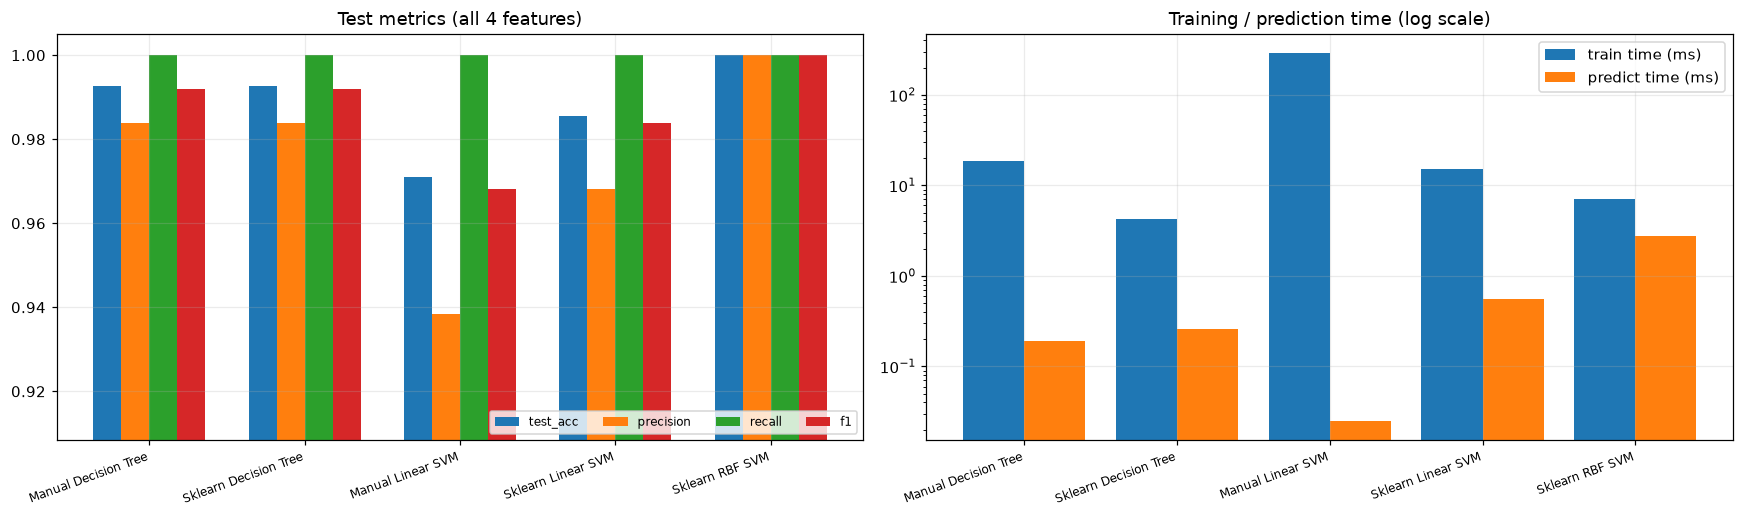

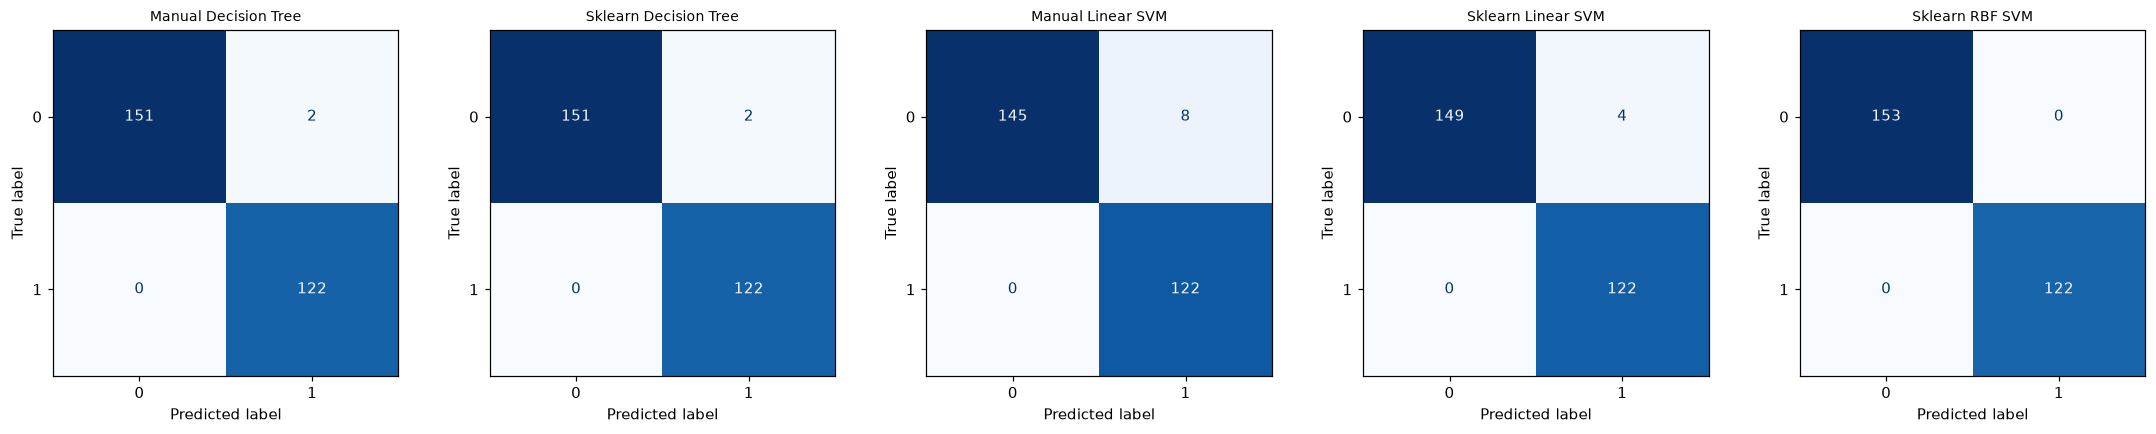

Manual DT  vs sklearn DT  prediction agreement: 1.0
Manual SVM vs sklearn SVM prediction agreement: 0.9855


In [15]:
# Metric bars
metrics = ["test_acc", "precision", "recall", "f1"]
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
w = 0.18
for i, mt in enumerate(metrics):
    axes[0].bar(np.arange(len(final)) + (i - 1.5) * w, final[mt], width=w, label=mt)
axes[0].set_xticks(range(len(final)))
axes[0].set_xticklabels(final.model, rotation=20, ha="right", fontsize=8)
lo = max(0.0, min(final[metrics].min()) - 0.03)
axes[0].set_ylim(lo, 1.005)
axes[0].set_title("Test metrics (all 4 features)")
axes[0].legend(ncol=4, fontsize=8, loc="lower right")

x = np.arange(len(final))
axes[1].bar(x - 0.2, final.train_time_s * 1000, 0.4, label="train time (ms)")
axes[1].bar(x + 0.2, final.predict_time_ms, 0.4, label="predict time (ms)")
axes[1].set_yscale("log")
axes[1].set_xticks(x)
axes[1].set_xticklabels(final.model, rotation=20, ha="right", fontsize=8)
axes[1].set_title("Training / prediction time (log scale)")
axes[1].legend()
savefig("D_metrics_and_timing")

# Confusion matrices
fig, axes = plt.subplots(1, len(final), figsize=(4 * len(final), 3.8))
for ax, name in zip(axes, final.model):
    ConfusionMatrixDisplay(confusion_matrix(y_test, preds[name])).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name, fontsize=9)
    ax.grid(False)
savefig("D_confusion_matrices")

# Agreement between manual and sklearn counterparts
print("Manual DT  vs sklearn DT  prediction agreement:",
      round(float((preds["Manual Decision Tree"] == preds["Sklearn Decision Tree"]).mean()), 4))
print("Manual SVM vs sklearn SVM prediction agreement:",
      round(float((preds["Manual Linear SVM"] == preds["Sklearn Linear SVM"]).mean()), 4))

### D.2 Tree depth vs SVM C: complexity / over-fitting check on four features
(Selected using the test set only for *illustration* of over-fitting behaviour, not for tuning.)

In [16]:
rows = []
for d in [1, 2, 3, 4, 5, 7, 10, None]:
    m = ManualDecisionTree("gini", max_depth=d).fit(X_train, y_train)
    rows.append({"model": "Manual DT", "setting": f"max_depth={d}",
                 "train_acc": accuracy_score(y_train, m.predict(X_train)),
                 "test_acc": accuracy_score(y_test, m.predict(X_test)), "complexity": f"{m.n_leaves} leaves"})
for C in [0.01, 0.1, 1, 10, 100]:
    m = ManualLinearSVM(C=C, lr=0.1, n_iters=3000).fit(Xs_train, ytr_pm4)
    rows.append({"model": "Manual Linear SVM", "setting": f"C={C}",
                 "train_acc": accuracy_score(y_train, m.predict01(Xs_train)),
                 "test_acc": accuracy_score(y_test, m.predict01(Xs_test)), "complexity": "5 params"})
for g in [0.01, 0.1, 1, 10, 50]:
    m = SVC(kernel="rbf", C=1.0, gamma=g).fit(Xs_train, y_train)
    rows.append({"model": "RBF SVM", "setting": f"gamma={g}",
                 "train_acc": accuracy_score(y_train, m.predict(Xs_train)),
                 "test_acc": accuracy_score(y_test, m.predict(Xs_test)),
                 "complexity": f"{len(m.support_vectors_)} SVs"})
complexity_df = pd.DataFrame(rows)
complexity_df["gap(train-test)"] = complexity_df.train_acc - complexity_df.test_acc
show(complexity_df.round(4), "D_complexity_overfitting")

,model,setting,train_acc,test_acc,complexity,gap(train-test)
0,Manual DT,max_depth=1,0.8423,0.8291,2 leaves,0.0132
1,Manual DT,max_depth=2,0.9088,0.8909,4 leaves,0.0179
2,Manual DT,max_depth=3,0.9435,0.9236,8 leaves,0.0198
3,Manual DT,max_depth=4,0.9727,0.9709,14 leaves,0.0017
4,Manual DT,max_depth=5,0.9945,0.9927,20 leaves,0.0018
5,Manual DT,max_depth=7,1.0000,0.9927,25 leaves,0.0073
6,Manual DT,max_depth=10,1.0000,0.9927,25 leaves,0.0073
7,Manual DT,max_depth=None,1.0000,0.9927,25 leaves,0.0073
8,Manual Linear SVM,C=0.01,0.9781,0.9709,5 params,0.0072
9,Manual Linear SVM,C=0.1,0.9854,0.9709,5 params,0.0145


### D.3 Automatic summary of the results above

In [17]:
best = final.loc[final.f1.idxmax()]
print("=" * 70)
print("SUMMARY (test set, 4 features)")
print("=" * 70)
print(final[["model", "test_acc", "precision", "recall", "f1", "train_time_s", "predict_time_ms"]]
      .round(4).to_string(index=False))
print(f"\nBest F1               : {best.model} ({best.f1:.4f})")
print(f"Fastest to train      : {final.loc[final.train_time_s.idxmin(), 'model']}")
print(f"Fastest to predict    : {final.loc[final.predict_time_ms.idxmin(), 'model']}")
print(f"Largest train-test gap: {final.loc[(final.train_acc - final.test_acc).idxmax(), 'model']} "
      f"({(final.train_acc - final.test_acc).max():.4f})")
print("\nFigures saved in ./plots :", len(os.listdir('plots')))
print("Tables  saved in ./results:", len(os.listdir('results')))

SUMMARY (test set, 4 features)
                model  test_acc  precision  recall     f1  train_time_s  predict_time_ms
 Manual Decision Tree    0.9927     0.9839     1.0 0.9919        0.0184           0.1928
Sklearn Decision Tree    0.9927     0.9839     1.0 0.9919        0.0043           0.2569
    Manual Linear SVM    0.9709     0.9385     1.0 0.9683        0.2931           0.0247
   Sklearn Linear SVM    0.9855     0.9683     1.0 0.9839        0.0152           0.5568
      Sklearn RBF SVM    1.0000     1.0000     1.0 1.0000        0.0071           2.7669

Best F1               : Sklearn RBF SVM (1.0000)
Fastest to train      : Sklearn Decision Tree
Fastest to predict    : Manual Linear SVM
Largest train-test gap: Manual Linear SVM (0.0145)

Figures saved in ./plots : 13
Tables  saved in ./results: 9
